In [ ]:
import matplotlib.pyplot as plt

import pandas as pd
import seaborn as sb
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

: 

In [30]:
# CARREGAR O CONJUNTO DE DADOS

df = pd.read_csv('pokemon_all_gen.csv')
df

,Numero,Nome,Tipo_1,Tipo_2,HP,Ataque,Defesa,Ataque_Especial,Defesa_Especial,Velocidade,Geracao,Lendario,Total
0,1,Bulbasaur,Grama,Veneno,45,49,49,65,65,45,1,Não,318
1,2,Ivysaur,Grama,Veneno,60,62,63,80,80,60,1,Não,405
2,3,Venusaur,Grama,Veneno,80,82,83,100,100,80,1,Não,525
3,4,Charmander,Fogo,NaN,39,52,43,60,50,65,1,Não,309
4,5,Charmeleon,Fogo,NaN,58,64,58,80,65,80,1,Não,405
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,1021,Iron Crown,Aço,Psíquico,90,72,100,122,108,98,9,Sim,590
1021,1022,Terapagos,Normal,NaN,90,90,110,130,110,60,9,Sim,590
1022,1023,Pecharunt,Veneno,Fantasma,40,110,75,130,75,50,9,Sim,480
1023,1024,Archaludon,Aço,Dragão,90,105,130,125,65,85,9,Não,600


In [31]:
# DEFINIR AS CARACTERÍSTICAS(X) E OS RÓTULOS (y)
# X recebe os stats de batalha, y recebe o Tipo_1 de cada Pokémon

colunas_stats = ['HP', 'Ataque', 'Defesa', 'Ataque_Especial', 'Defesa_Especial', 'Velocidade']
X = df[colunas_stats].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['Tipo_1'])
print(f'Tipos únicos: {list(label_encoder.classes_)}')

Tipos únicos: ['Aço', 'Dragão', 'Elétrico', 'Fada', 'Fantasma', 'Fogo', 'Gelo', 'Grama', 'Inseto', 'Lutador', 'Normal', 'Pedra', 'Psíquico', 'Sombrio', 'Terra', 'Veneno', 'Voador', 'Água']


In [32]:
# DIVIDIR O CONJUNTO DE DADOS E TREINO E TESTE (80% TREINO E 20% TESTE)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
# CRIAR O MODELO KNN (COM 3 VIZINHOS MAIS PRÓXIMOS)

knn = KNeighborsClassifier(n_neighbors = 14)

In [34]:
# TREINAR MODELO

knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=14)

In [35]:
# FAZER PREVISÕES NO CONJUNTO TESTE

y_pred = knn.predict(X_test)

In [36]:
# AVALIAR A ACURACIA DO MODELO

accuracy = accuracy_score(y_test, y_pred)

print(f"Acurácia do modelo: {accuracy * 100:.2f}%")

Acurácia do modelo: 20.49%


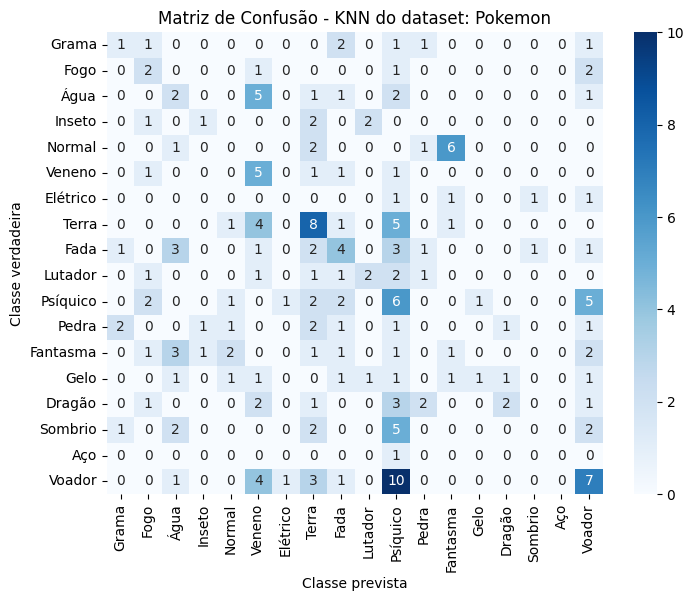

In [37]:
# Gerar a matriz de confusão (data_ser iris objeto)
cm = confusion_matrix(y_test,y_pred)

# Plotar a matriz de confusão
plt.figure(figsize=(8,6))
sb.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=df["Tipo_1"].unique(), yticklabels=df["Tipo_1"].unique())
plt.title("Matriz de Confusão - KNN do dataset: Pokemon")
plt.xlabel("Classe prevista")
plt.ylabel("Classe verdadeira")
plt.show()